# FX.1 — Análisis exploratorio de píxeles

Figuras del análisis **exploratorio** FX.1 (`docs/plan_exploratorio_pixeles.md`, etiqueta `plan-pixeles`; bitácora `docs/bitacora/FX_pixeles.md`). No figura en el protocolo preregistrado, no modifica veredictos y no usa el conjunto de prueba: B y C se calcularon en val y D en train.

Toda cifra se lee de archivos versionados:
- `results/fx_pixeles/local/resultados.json`, `b_por_muestra.csv` y `arreglos.npz` (B y D, Kaggle CPU);
- `results/fx_pixeles/gpu/resultados.json` y `arreglos.npz` (C1 y C2, Kaggle GPU T4).

Las paletas de color solo se usan en mapas de calor (oclusión y t). Las figuras con imágenes del generador están al final y requieren `TT_DATA_ROOT`.

In [1]:
import csv
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'src'))
from viz import style
from src.fase_x import pixeles_comun as pc

style.apply()
RES = REPO / 'results' / 'fx_pixeles'
FIG = RES / 'figures'
TECHS = ['gray_scott', 'perlin', 'lorenz']
L = json.loads((RES / 'local' / 'resultados.json').read_text(encoding='utf-8'))
G = json.loads((RES / 'gpu' / 'resultados.json').read_text(encoding='utf-8'))
ZL = np.load(RES / 'local' / 'arreglos.npz')
ZG = np.load(RES / 'gpu' / 'arreglos.npz')
for d in (L, G):
    assert d['meta']['smoke'] is False and d['meta']['limit'] is None
    assert d['meta']['plan']['sha256'] == '2972e527e84b52d2380f53df494725964f1ac470111b9c9fb7dbded277e21caa'
rows = sorted((r for r in csv.DictReader(open(REPO / 'meta' / 'sample_index.csv', encoding='utf-8')) if r['split'] == 'val'),
              key=lambda r: r['sample_id'])
pc.exigir_split(rows, 'val')
y = np.array([int(r['y_true']) for r in rows])
print('commit de ejecución:', L['meta']['git_commit'][:7], G['meta']['git_commit'][:7], '| n val =', len(y), '| depresivos =', y.sum())

commit de ejecución: 531acb0 531acb0 | n val = 114 | depresivos = 44


## B. Traslape entre atribución y pendiente (val; Gray-Scott y Perlin)

**Figura 1.** Distribución por muestra de:
- **arriba:** el Spearman entre la masa del mapa de F3.7 y la pendiente media por parche (B1);
- **abajo:** el ΔDice del 10 % superior frente a la nula diédrica (B2).

El modelo real va en color y el permutado de F3.6 en gris; la línea marca la media. Si real y permutado coinciden, la coincidencia no depende de haber aprendido la etiqueta (B3).

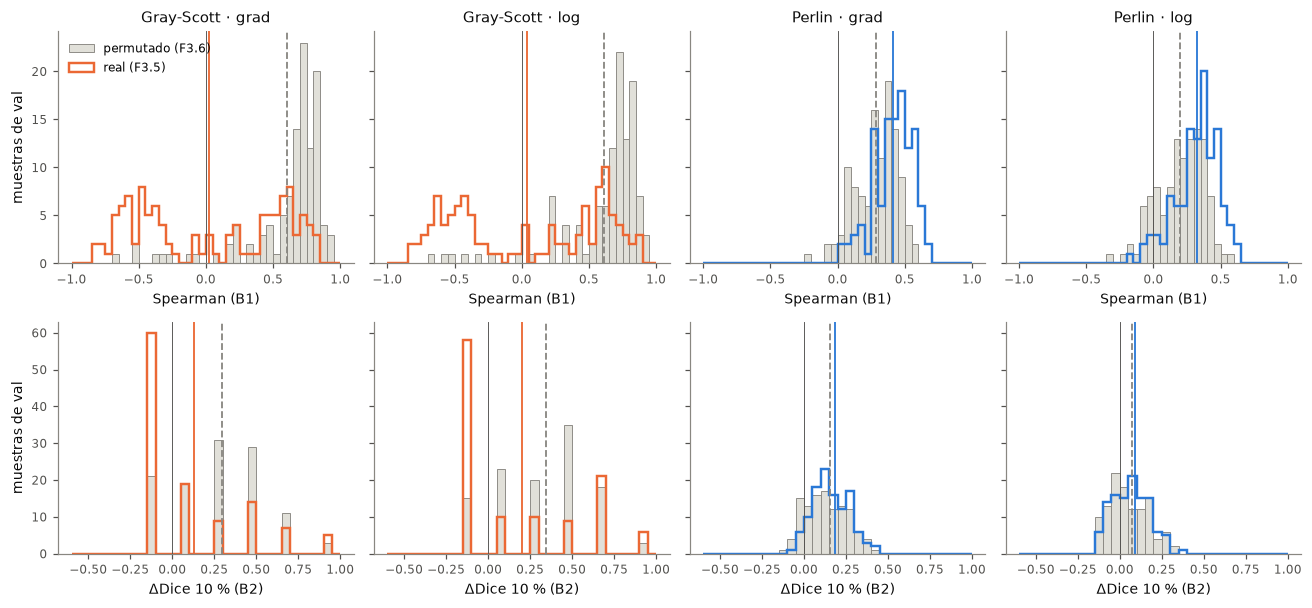

In [2]:
B = pd.read_csv(RES / 'local' / 'b_por_muestra.csv')
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharey='row')
for j, (t, m) in enumerate([(t, m) for t in ('gray_scott', 'perlin') for m in ('grad', 'log')]):
    d = B[B.tecnica == t]
    for i, (col, lab) in enumerate(((f'spearman_{{}}_{m}', 'Spearman (B1)'), (f'delta_dice_{{}}_{m}_q0.1', 'ΔDice 10 % (B2)'))):
        ax = axes[i, j]
        bins = np.linspace(-1, 1, 41) if i == 0 else np.linspace(-0.6, 1, 33)
        ax.hist(d[col.format('perm')].dropna(), bins=bins, color=style.GRID, edgecolor=style.MUTED, lw=0.6, label='permutado (F3.6)')
        ax.hist(d[col.format('real')].dropna(), bins=bins, histtype='step', color=style.TECH_COLOR[t], lw=1.6, label='real (F3.5)')
        for f, c, ls in (('perm', style.MUTED, '--'), ('real', style.TECH_COLOR[t], '-')):
            ax.axvline(d[col.format(f)].mean(), color=c, ls=ls, lw=1.2)
        ax.axvline(0, color=style.INK_SECONDARY, lw=0.6)
        if i == 0:
            ax.set_title(f'{style.TECH_LABEL[t]} · {m}')
        ax.set_xlabel(lab)
        if j == 0:
            ax.set_ylabel('muestras de val')
axes[0, 0].legend(loc='upper left')
fig.tight_layout()
style.save(fig, FIG / 'b_spearman_dice_real_vs_permutado')
plt.show()

In [3]:
filas = []
for t in ('gray_scott', 'perlin'):
    b = L['resultados']['B'][t]
    for m in ('grad', 'log'):
        f = lambda r: f"{r['media']:+.3f} [{r['ic_inf']:+.3f}, {r['ic_sup']:+.3f}]"
        filas.append({'técnica': t, 'mapa': m, 'B1 real': f(b['B1'][f'real|{m}']), 'B1 permutado': f(b['B1'][f'perm|{m}']),
                      'B2 ΔDice 10 % real': f(b['B2'][f'real|{m}|q0.1']['delta']), 'B3 (B1 real − perm)': f(b['B3'][f'B1|{m}']),
                      'B4 p Holm': L['resultados']['B']['H-B'][f'{t}|{m}']['p_holm'], 'B4 biserial': b['B4'][m]['biserial']})
pd.DataFrame(filas)

,técnica,mapa,B1 real,B1 permutado,B2 ΔDice 10 % real,B3 (B1 real − perm),B4 p Holm,B4 biserial
0,gray_scott,grad,"+0.025 [-0.073, +0.122]","+0.603 [+0.541, +0.659]","+0.130 [+0.075, +0.186]","-0.578 [-0.688, -0.471]",0.000371,0.431818
1,gray_scott,log,"+0.041 [-0.061, +0.140]","+0.608 [+0.546, +0.664]","+0.198 [+0.133, +0.264]","-0.567 [-0.680, -0.458]",0.000371,0.436364
2,perlin,grad,"+0.414 [+0.387, +0.440]","+0.286 [+0.256, +0.314]","+0.184 [+0.165, +0.204]","+0.129 [+0.113, +0.145]",0.218303,-0.137662
3,perlin,log,"+0.324 [+0.294, +0.353]","+0.198 [+0.166, +0.229]","+0.087 [+0.068, +0.107]","+0.126 [+0.111, +0.142]",0.215062,-0.179870


## C1. Suavizado dirigido a la pendiente alta (val; tres técnicas)

**Figura 2.**
- **Izquierda:** S = |Δp_dep| con la máscara de pendiente alta − media de |Δp_dep| con la misma máscara desplazada (20 sorteos). Media con IC al 95 %; los rombos rellenos son las condiciones que rechaza Holm (familia H-C, m = 12). S > 0 significa que quitar la pendiente alta altera más la predicción que quitar la misma área en otra posición.
- **Derecha:** ΔF1-val con la máscara alta (rombo) frente a los 20 sorteos desplazados (puntos grises) y la máscara de pendiente baja (aspa).

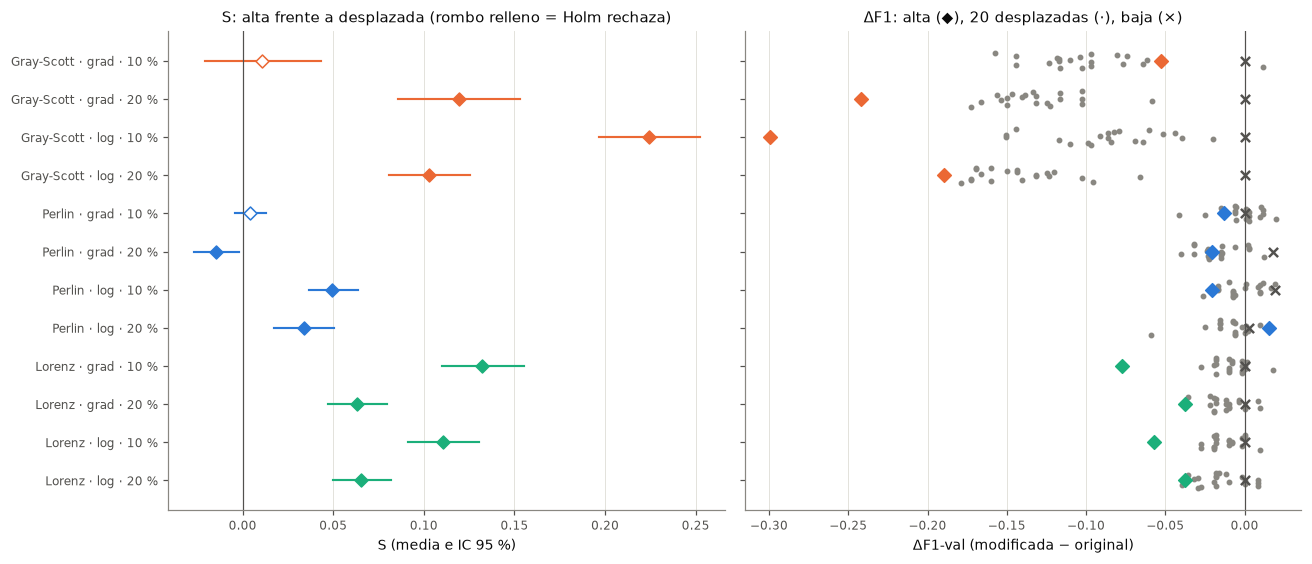

In [4]:
conds = [(t, m, q) for t in TECHS for m in ('grad', 'log') for q in (0.1, 0.2)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
from sklearn.metrics import f1_score
f1 = lambda yy, p: f1_score(yy, p > 0.5, average='macro')  # noqa: E731
for i, (t, m, q) in enumerate(conds):
    r = G['resultados']['C1'][t]['por_condicion'][f'{m}|q{q}']
    h = G['resultados']['C1']['H-C'][f'{t}|{m}|q{q}']
    yy = len(conds) - 1 - i
    c = style.TECH_COLOR[t]
    axes[0].plot([r['S']['ic_inf'], r['S']['ic_sup']], [yy, yy], color=c, lw=1.4)
    axes[0].scatter(r['S']['media'], yy, marker='D', s=36, color=c if h['reject'] else 'white', edgecolors=c, zorder=3)
    arr = ZG[f'C1|{t}|{m}|q{q}|p_por_semilla'].mean(2)
    p0 = ZG[f'C1|{t}|p_original'].mean(1)
    f0 = f1(y, p0)
    desp = [f1(y, arr[:, 2 + k]) - f0 for k in range(G['meta']['k_sorteos'])]
    axes[1].scatter(desp, np.full(len(desp), yy) + np.linspace(-0.2, 0.2, len(desp)), s=8, color=style.MUTED, zorder=2)
    axes[1].scatter(r['delta_f1']['alta'], yy, marker='D', s=40, color=c, zorder=3)
    axes[1].scatter(r['delta_f1']['baja'], yy, marker='x', s=36, color=style.INK_SECONDARY, zorder=3)
    np.testing.assert_allclose(f1(y, arr[:, 0]) - f0, r['delta_f1']['alta'])
labels = [f"{style.TECH_LABEL[t]} · {m} · {int(q * 100)} %" for t, m, q in conds][::-1]
axes[0].set_yticks(range(len(conds)))
axes[0].set_yticklabels(labels)
for ax, xl in zip(axes, ('S (media e IC 95 %)', 'ΔF1-val (modificada − original)')):
    ax.axvline(0, color=style.INK_SECONDARY, lw=0.8)
    ax.set_xlabel(xl)
    ax.grid(axis='x')
axes[0].set_title('S: alta frente a desplazada (rombo relleno = Holm rechaza)')
axes[1].set_title('ΔF1: alta (◆), 20 desplazadas (·), baja (×)')
fig.tight_layout()
style.save(fig, FIG / 'c1_s_y_delta_f1')
plt.show()

## C2. Mapa de oclusión (val; tres técnicas)

**Figura 3.** Oclusión media por clase real de los finalistas (media de 5 semillas): |Δp_dep| al reemplazar cada parche de 32 px por su versión desenfocada (σ = 8). En la tercera columna, la diferencia depresivo − no depresivo. El título indica la lectura de la cordura por datos (criterio relativo de F4.3).

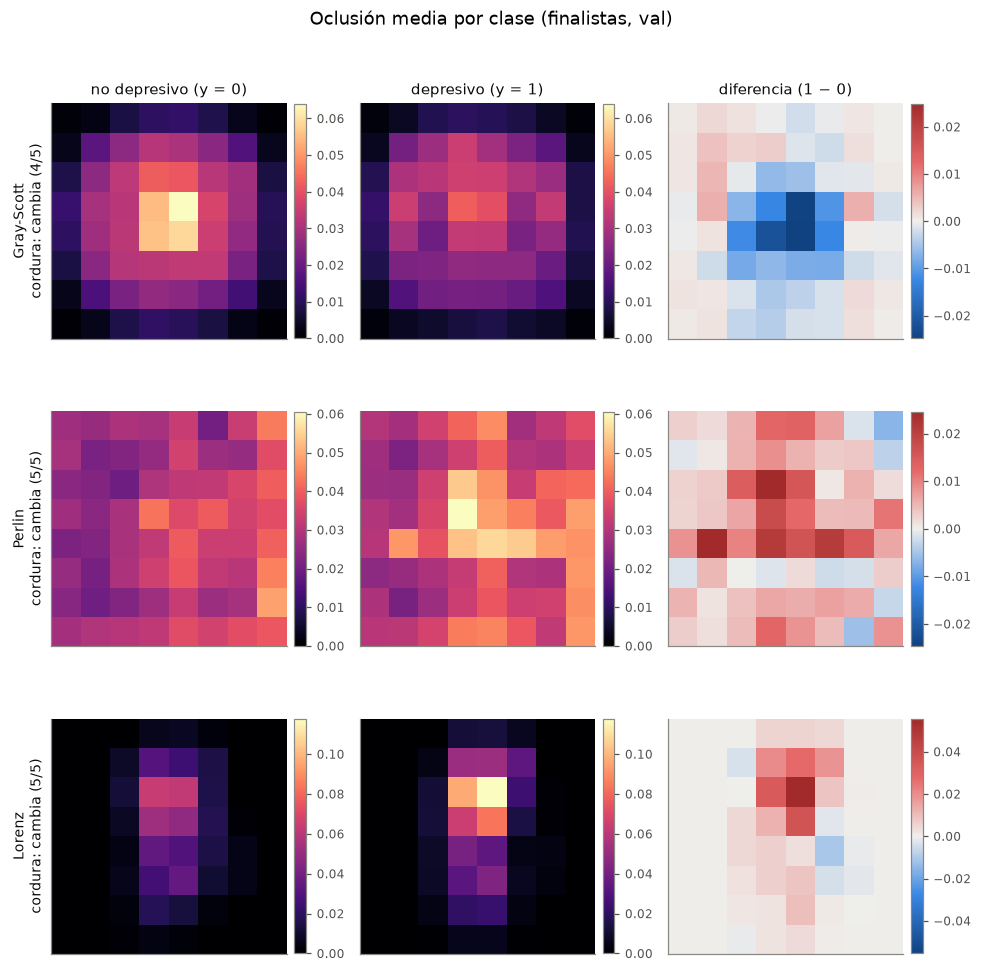

,técnica,cordura,mediana real–perm por semilla,rango pares reales,Spearman O–grad,Spearman O–log
0,gray_scott,cambia,"[0.696, 0.621, 0.691, 0.642, 0.72]","[0.719, 0.763]",0.756,0.754
1,perlin,cambia,"[0.006, 0.094, 0.132, 0.07, 0.093]","[0.237, 0.667]",0.175,0.134
2,lorenz,cambia,"[0.979, 0.976, 0.976, 0.973, 0.977]","[0.983, 0.993]",0.887,0.878


In [5]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, t in enumerate(TECHS):
    o = np.mean([ZG[f'C2|{t}|real|s{s}'] for s in pc.SEEDS], axis=0)
    m0, m1 = o[y == 0].mean(0), o[y == 1].mean(0)
    vmax = max(m0.max(), m1.max())
    for j, (mm, lab) in enumerate(((m0, 'no depresivo (y = 0)'), (m1, 'depresivo (y = 1)'))):
        im = axes[i, j].imshow(mm, cmap='magma', vmin=0, vmax=vmax)
        axes[i, j].set_title(lab if i == 0 else '')
        fig.colorbar(im, ax=axes[i, j], fraction=0.046, pad=0.03)
    d = m1 - m0
    lim = np.abs(d).max()
    im = axes[i, 2].imshow(d, cmap=style.DIVERGING, vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=axes[i, 2], fraction=0.046, pad=0.03)
    if i == 0:
        axes[i, 2].set_title('diferencia (1 − 0)')
    c = G['resultados']['C2'][t]['cordura']
    axes[i, 0].set_ylabel(f"{style.TECH_LABEL[t]}\ncordura: {c['global']} ({sum(x == 'cambia' for x in c['por_semilla'])}/5)")
    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Oclusión media por clase (finalistas, val)', y=1.0)
fig.tight_layout()
style.save(fig, FIG / 'c2_oclusion_por_clase')
plt.show()
pd.DataFrame([{'técnica': t, 'cordura': G['resultados']['C2'][t]['cordura']['global'],
               'mediana real–perm por semilla': [round(v, 3) for v in G['resultados']['C2'][t]['cordura']['valores']],
               'rango pares reales': [round(v, 3) for v in G['resultados']['C2'][t]['cordura']['rango_referencia']],
               'Spearman O–grad': round(G['resultados']['C2'][t]['corr_pendiente']['grad']['media'], 3),
               'Spearman O–log': round(G['resultados']['C2'][t]['corr_pendiente']['log']['media'], 3)} for t in TECHS])

## D. Diferencias de pendiente entre clases (train; sin modelo)

**Figura 4.** Mapa t de Welch por píxel (depresivo − no depresivo) de `grad` y `log` en Gray-Scott y Lorenz, con el contorno de los clústeres con p < 0.05 (prueba por clústeres, |t| > 2.58, 1,000 permutaciones). Perlin se analiza con la media por imagen (tabla).

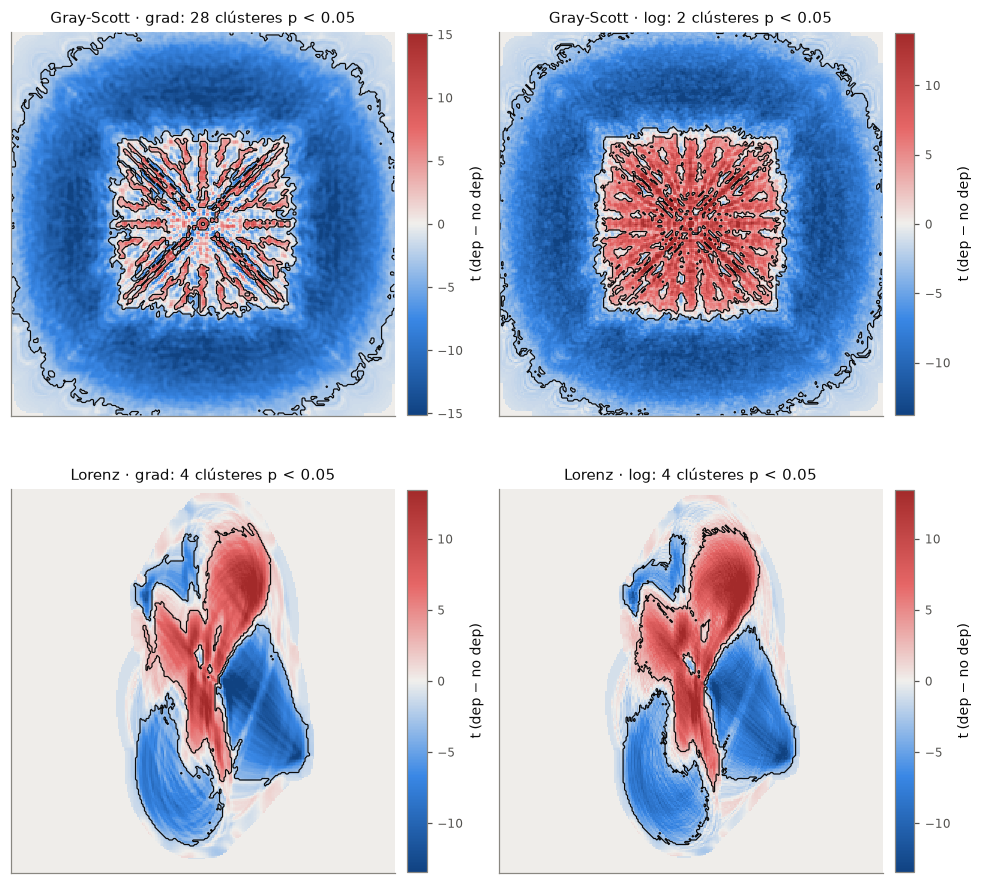

,técnica,mapa,p familia,p Holm (H-D),efecto
0,gray_scott,grad,9.990010e-04,3.996004e-03,28 clústeres; mayor: -44614 px
1,gray_scott,log,9.990010e-04,3.996004e-03,2 clústeres; mayor: -42931 px
2,perlin,grad,6.672157e-55,4.003294e-54,biserial +0.614
3,perlin,log,5.004835e-32,2.502418e-31,biserial +0.463
4,lorenz,grad,9.990010e-04,3.996004e-03,4 clústeres; mayor: +5591 px
5,lorenz,log,9.990010e-04,3.996004e-03,4 clústeres; mayor: +5939 px


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8.4))
for i, t in enumerate(('gray_scott', 'lorenz')):
    for j, m in enumerate(('grad', 'log')):
        tm = ZL[f'{t}|{m}|t'].astype(np.float64)
        lim = np.nanpercentile(np.abs(tm), 99.5)
        ax = axes[i, j]
        im = ax.imshow(tm, cmap=style.DIVERGING, vmin=-lim, vmax=lim)
        sig = L['resultados']['D'][t][m]['clusteres_p_menor_005']
        todos = pc.clusteres(tm, pc.FIJOS['umbral_t'])
        mask = np.zeros_like(tm, dtype=bool)
        from scipy.ndimage import label
        for signo in (1, -1):
            lab, n = label(signo * tm > pc.FIJOS['umbral_t'], structure=np.ones((3, 3), int))
            for k in range(1, n + 1):
                yy, xx = np.nonzero(lab == k)
                if any(c['area'] == len(yy) and abs(c['centroide_yx'][0] - yy.mean()) < 1e-6
                       and abs(c['centroide_yx'][1] - xx.mean()) < 1e-6 for c in sig):
                    mask |= lab == k
        ax.contour(mask, levels=[0.5], colors=style.INK, linewidths=0.8)
        ax.set_title(f"{style.TECH_LABEL[t]} · {m}: {len(sig)} clústeres p < 0.05")
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label='t (dep − no dep)')
fig.tight_layout()
style.save(fig, FIG / 'd_mapas_t_clusteres')
plt.show()
pd.DataFrame([{'técnica': t, 'mapa': m, 'p familia': L['resultados']['D'][t][m]['p_familia'],
               'p Holm (H-D)': L['resultados']['D']['H-D'][f'{t}|{m}']['p_holm'],
               'efecto': (f"biserial {L['resultados']['D'][t][m]['biserial']:+.3f}" if t == 'perlin' else
                          f"{len(L['resultados']['D'][t][m]['clusteres_p_menor_005'])} clústeres; mayor: "
                          f"{L['resultados']['D'][t][m]['clusteres_p_menor_005'][0]['signo']}"
                          f"{L['resultados']['D'][t][m]['clusteres_p_menor_005'][0]['area']} px")}
              for t in TECHS for m in ('grad', 'log')])

## Figuras con imágenes (requieren `TT_DATA_ROOT`)

Ejemplos por técnica de la imagen, `grad` y `log` (escala de grises), y de las imágenes modificadas en C1: alta, desplazada, azar y baja. Las imágenes del generador no están en el repositorio. Esta celda solo corre si `TT_DATA_ROOT` apunta a `tt2-insumos`; usa la primera muestra de val de cada clase y el primer sorteo del generador de C1.

In [7]:
if os.environ.get('TT_DATA_ROOT'):
    from src.fase_x.pixeles_local import imagenes
    res = pc.check_resoluciones(json.loads((RES / 'resoluciones.json').read_text(encoding='utf-8')))
    idx = [int(np.argmax(y == 0)), int(np.argmax(y == 1))]
    fig, axes = plt.subplots(3, 7, figsize=(15, 6.8))
    for i, t in enumerate(TECHS):
        imgs, _ = imagenes(t, [rows[k] for k in idx], 'val')
        im = imgs[1]
        pend = pc.mapas_pendiente(im, 1, res['sobel_borde'])
        k = res['k_c1'][0]
        d4 = pc.desenfocar(im, 4)
        rng = np.random.default_rng(res['semilla_rng'])
        _, _, _, desp, azar = next(pc.sorteos_c1(rng, ('grad',), [0.1], 1, 1, {0.1: k}, res))
        mod = pc.imagenes_c1(im, pend['grad'], 0.1, k, desp, azar, d4)
        panel = [(im, 'imagen (y = 1)'), (pend['grad'], 'grad'), (pend['log'], 'log'), (mod[0], 'C1 alta 10 %'),
                 (mod[2], f'C1 desplazada {desp[0]}'), (mod[3], 'C1 azar'), (mod[1], 'C1 baja 10 %')]
        for j, (a, lab) in enumerate(panel):
            axes[i, j].imshow(a, cmap='gray')
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
            if i == 0:
                axes[i, j].set_title(lab)
        axes[i, 0].set_ylabel(style.TECH_LABEL[t])
    fig.tight_layout()
    style.save(fig, FIG / 'ejemplos_pendiente_c1')
    plt.show()
else:
    print('TT_DATA_ROOT no definido: la figura de ejemplos con imágenes no se genera aquí')

TT_DATA_ROOT no definido: la figura de ejemplos con imágenes no se genera aquí
